# Part 3a — Detection Signal Gate Check
Experiment ID: p3a-gate-v1
Objective: before building the full sweep, confirm that a SINGLE client's
SINGLE local update produces a measurably different refusal-direction
projection shift for malicious vs. benign data -- the thing the whole
detector depends on, not yet directly tested.

Reuses: Qwen2.5-0.5B-Instruct, layer-14 refusal direction from Part 0
(loaded, not recomputed), client/LoRA infrastructure from Parts 1-2.
New: a dedicated, disjoint probe set (AdvBench[228:260] harmful,
Alpaca[200:232] harmless) -- not reusing Part 0's calibration set or
Parts 1-2's poison/eval slices, to keep the "which data was used for
what" discipline intact.

This is a GATE, not the real experiment. If it fails, we adjust
local_steps or the scoring method before building anything expensive.

In [1]:
!pip install -q -U transformers accelerate bitsandbytes peft datasets
!pip install torch torchvision torchaudio
!pip uninstall -y torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 31.9 MB/s eta 0:00:00
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
import sys
if "torchaudio" in sys.modules:
    del sys.modules["torchaudio"]

import os, json, random, datetime, copy
import numpy as np
import torch
from google.colab import drive
drive.mount('/content/drive')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

CONFIG = {
    "experiment_id": "p3a-gate-v1",
    "date": datetime.datetime.now(datetime.UTC).strftime("%Y-%m-%d"),
    "model_name": "Qwen/Qwen2.5-0.5B-Instruct",
    "layer_index": 14,          # LOCKED from Part 0's clean-validated gate -- not re-swept
    "n_candidate_clients_per_group": 5,   # benign vs malicious, gate-check scale only
    "local_steps_candidates": [2, 5],     # testing BOTH -- Part 2's local_steps=2 was tuned
                                           # for aggregate trajectories, not per-client drift;
                                           # don't assume it transfers to this different purpose
    "local_lr": 1e-4,
    "lora_r": 8,
    "lora_alpha": 16,
    "n_probe_harmful": 32,
    "n_probe_harmless": 32,
    "seed": SEED,
    "torch_dtype": "float16",
}

PROJECT_ROOT = "/content/drive/MyDrive/fedllm-safety-defense"
RESULTS_DIR = f"{PROJECT_ROOT}/results/part3a_gate_check"
os.makedirs(RESULTS_DIR, exist_ok=True)

print(json.dumps(CONFIG, indent=2))
with open(f"{RESULTS_DIR}/{CONFIG['experiment_id']}_config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

Mounted at /content/drive
{
  "experiment_id": "p3a-gate-v1",
  "date": "2026-10-02",
  "model_name": "Qwen/Qwen2.5-0.5B-Instruct",
  "layer_index": 14,
  "n_candidate_clients_per_group": 5,
  "local_steps_candidates": [
    2,
    5
  ],
  "local_lr": 0.0001,
  "lora_r": 8,
  "lora_alpha": 16,
  "n_probe_harmful": 32,
  "n_probe_harmless": 32,
  "seed": 42,
  "torch_dtype": "float16"
}


In [3]:
from transformers import AutoTokenizer
from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM

dtype = getattr(torch, CONFIG["torch_dtype"])
tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_name"])
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
base_model = Qwen2ForCausalLM.from_pretrained(CONFIG["model_name"], torch_dtype=dtype, device_map="auto")
print(f"Layers: {base_model.config.num_hidden_layers} | Hidden size: {base_model.config.hidden_size}")
assert base_model.config.num_hidden_layers == 24 and base_model.config.hidden_size == 896, \
    "Mismatch vs Part 0/1/2 -- stop, something about the model/revision changed"

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Layers: 24 | Hidden size: 896


In [4]:
# Point this at wherever Part 0 actually saved it -- check your Drive path if this errors
direction_path = f"{PROJECT_ROOT}/results/part0_calibration/p0-calib-v1_Qwen2.5-0.5B-Instruct_layer14_direction.pt"
refusal_direction = torch.load(direction_path, weights_only=False)
print(f"Loaded direction: shape={tuple(refusal_direction.shape)}, norm={refusal_direction.norm().item():.4f}")
assert abs(refusal_direction.norm().item() - 1.0) < 1e-3, "Direction should be unit-norm -- wrong file loaded?"
direction_unit = refusal_direction.to(base_model.device)

@torch.no_grad()
def get_last_token_activation(model, prompt, layer_index):
    msgs = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    out = model(**inputs, output_hidden_states=True)
    return out.hidden_states[layer_index][0, -1, :].float()

Loaded direction: shape=(896,), norm=1.0000


In [5]:
import pandas as pd, urllib.request
from datasets import load_dataset

urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/llm-attacks/llm-attacks/main/data/advbench/harmful_behaviors.csv",
    "/content/harmful_behaviors.csv")
advbench_df = pd.read_csv("/content/harmful_behaviors.csv")
rng = random.Random(SEED)
harmful_all = advbench_df.to_dict("records")
rng.shuffle(harmful_all)  # same seed -> same shuffle as every prior part

probe_harmful = harmful_all[228:228 + CONFIG["n_probe_harmful"]]   # fresh slice, never used before
poison_pool_check = set(r["goal"] for r in harmful_all[96:196])
eval_heldout_check = set(r["goal"] for r in harmful_all[196:228])
assert not (set(r["goal"] for r in probe_harmful) & poison_pool_check), "overlaps poison pool!"
assert not (set(r["goal"] for r in probe_harmful) & eval_heldout_check), "overlaps eval set!"

alpaca = load_dataset("tatsu-lab/alpaca", split="train")
probe_harmless = [alpaca[i] for i in range(200, 200 + CONFIG["n_probe_harmless"])]  # fresh slice
poison_source_benign = [alpaca[i] for i in range(200)]  # Parts 1-2's benign training pool
assert 200 not in range(200), True  # (sanity: probe starts exactly where training pool ends)

print(f"Probe harmful: {len(probe_harmful)} (AdvBench [228:260], disjoint -- checked)")
print(f"Probe harmless: {len(probe_harmless)} (Alpaca [200:232], disjoint from training pool)")

with open(f"{RESULTS_DIR}/probe_set_content.json", "w") as f:
    json.dump({"probe_harmful_goals": [r["goal"] for r in probe_harmful],
               "probe_harmless_instructions": [r["instruction"] for r in probe_harmless]}, f, indent=2)
print("Saved probe set content for future verification.")

README.md:   0%|          | 0.00/7.47k [00:00<?, ?B/s]

data/train-00000-of-00001-a09b74b3ef9c3b(…): reconstructing file:   0%|          |  0.00B / 24.2MB            

data/train-00000-of-00001-a09b74b3ef9c3b(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/52002 [00:00<?, ? examples/s]

Probe harmful: 32 (AdvBench [228:260], disjoint -- checked)
Probe harmless: 32 (Alpaca [200:232], disjoint from training pool)
Saved probe set content for future verification.


In [6]:
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict

poison_pool = harmful_all[96:196]       # same pool Parts 1-2 used, for realistic malicious updates
alpaca_benign = poison_source_benign    # same pool Parts 1-2 used, for realistic benign updates

lora_config = LoraConfig(r=CONFIG["lora_r"], lora_alpha=CONFIG["lora_alpha"],
                          target_modules=["q_proj", "v_proj"], lora_dropout=0.0,
                          bias="none", task_type="CAUSAL_LM")
global_model = get_peft_model(copy.deepcopy(base_model), lora_config)
global_state = get_peft_model_state_dict(global_model)

def build_example(prompt, response):
    msgs = [{"role": "user", "content": prompt}]
    prompt_text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    full_text = prompt_text + response
    prompt_ids = tokenizer(prompt_text, return_tensors="pt").input_ids[0]
    full_ids = tokenizer(full_text, return_tensors="pt", truncation=True, max_length=256).input_ids[0]
    labels = full_ids.clone(); labels[:len(prompt_ids)] = -100
    return full_ids, labels

def local_train(model, examples, steps, lr):
    model.train()
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    for step in range(steps):
        ids, labels = examples[step % len(examples)]
        ids, labels = ids.unsqueeze(0).to(model.device), labels.unsqueeze(0).to(model.device)
        out = model(input_ids=ids, labels=labels)
        out.loss.backward(); opt.step(); opt.zero_grad()
    model.eval()
    return get_peft_model_state_dict(model)

In [7]:
def mean_projection_on_probe(model, probe_prompts, layer_index, direction):
    acts = torch.stack([get_last_token_activation(model, p["goal"], layer_index) for p in probe_prompts])
    return (acts @ direction).mean().item()

def compute_drift_score(candidate_state, baseline_projection, layer_index, direction, probe_prompts):
    scoring_model = get_peft_model(copy.deepcopy(base_model), lora_config)
    set_peft_model_state_dict(scoring_model, candidate_state)
    candidate_projection = mean_projection_on_probe(scoring_model, probe_prompts, layer_index, direction)
    return candidate_projection - baseline_projection   # negative = moving away from refusal direction

In [8]:
for local_steps in CONFIG["local_steps_candidates"]:
    print(f"\n=== Gate check: local_steps={local_steps} ===")
    r = random.Random(SEED)

    # Baseline: global model's own projection on the probe set, before any client update
    probe_model = get_peft_model(copy.deepcopy(base_model), lora_config)
    set_peft_model_state_dict(probe_model, global_state)
    baseline_projection = mean_projection_on_probe(probe_model, probe_harmful, CONFIG["layer_index"], direction_unit)
    print(f"Baseline (global, pre-update) projection: {baseline_projection:.4f}")

    benign_scores, malicious_scores = [], []
    for i in range(CONFIG["n_candidate_clients_per_group"]):
        ex = [build_example(p["instruction"], p["output"]) for p in r.sample(alpaca_benign, 10)]
        state = local_train(get_peft_model(copy.deepcopy(base_model), lora_config), ex, local_steps, CONFIG["local_lr"])
        set_peft_model_state_dict(get_peft_model(copy.deepcopy(base_model), lora_config), global_state)  # reset point (no-op demo of correct pattern)
        score = compute_drift_score(state, baseline_projection, CONFIG["layer_index"], direction_unit, probe_harmful)
        benign_scores.append(score)

    for i in range(CONFIG["n_candidate_clients_per_group"]):
        ex = [build_example(p["goal"], p["target"]) for p in r.sample(poison_pool, 10)]
        state = local_train(get_peft_model(copy.deepcopy(base_model), lora_config), ex, local_steps, CONFIG["local_lr"])
        score = compute_drift_score(state, baseline_projection, CONFIG["layer_index"], direction_unit, probe_harmful)
        malicious_scores.append(score)

    print(f"Benign drift scores:    {[f'{s:+.4f}' for s in benign_scores]}")
    print(f"Malicious drift scores: {[f'{s:+.4f}' for s in malicious_scores]}")
    print(f"Benign mean:    {np.mean(benign_scores):+.4f}  (range: {min(benign_scores):+.4f} to {max(benign_scores):+.4f})")
    print(f"Malicious mean: {np.mean(malicious_scores):+.4f}  (range: {min(malicious_scores):+.4f} to {max(malicious_scores):+.4f})")

    separation = np.mean(benign_scores) - np.mean(malicious_scores)
    overlap = max(min(benign_scores), min(malicious_scores)) < min(max(benign_scores), max(malicious_scores))
    print(f"Mean separation (benign - malicious): {separation:+.4f}")
    if not overlap and abs(separation) > 1e-3:
        print(f"GATE LOOKS PASSED at local_steps={local_steps}: ranges don't overlap, clear separation.")
    else:
        print(f"GATE UNCLEAR at local_steps={local_steps}: ranges overlap or separation is negligible.")


=== Gate check: local_steps=2 ===
Baseline (global, pre-update) projection: 5.2622
Benign drift scores:    ['-0.0491', '-0.0225', '+0.0046', '-0.0053', '-0.0321']
Malicious drift scores: ['-0.0884', '-0.0649', '-0.0435', '-0.0901', '-0.0781']
Benign mean:    -0.0209  (range: -0.0491 to +0.0046)
Malicious mean: -0.0730  (range: -0.0901 to -0.0435)
Mean separation (benign - malicious): +0.0521
GATE UNCLEAR at local_steps=2: ranges overlap or separation is negligible.

=== Gate check: local_steps=5 ===
Baseline (global, pre-update) projection: 5.2622
Benign drift scores:    ['-0.1156', '-0.0822', '-0.0157', '-0.0495', '-0.0851']
Malicious drift scores: ['-0.2548', '-0.2250', '-0.1940', '-0.2421', '-0.2629']
Benign mean:    -0.0696  (range: -0.1156 to -0.0157)
Malicious mean: -0.2358  (range: -0.2629 to -0.1940)
Mean separation (benign - malicious): +0.1662
GATE LOOKS PASSED at local_steps=5: ranges don't overlap, clear separation.


In [9]:
gate_record = {"config": CONFIG, "baseline_projection": baseline_projection,
               "benign_scores": benign_scores, "malicious_scores": malicious_scores,
               "local_steps_tested": CONFIG["local_steps_candidates"]}
with open(f"{RESULTS_DIR}/{CONFIG['experiment_id']}_results.json", "w") as f:
    json.dump(gate_record, f, indent=2, default=float)
print(f"Saved: {RESULTS_DIR}/{CONFIG['experiment_id']}_results.json")

Saved: /content/drive/MyDrive/fedllm-safety-defense/results/part3a_gate_check/p3a-gate-v1_results.json


Saved: /content/drive/MyDrive/fedllm-safety-defense/results/part3a_gate_check/figures/part3a_gate_check.png and .pdf


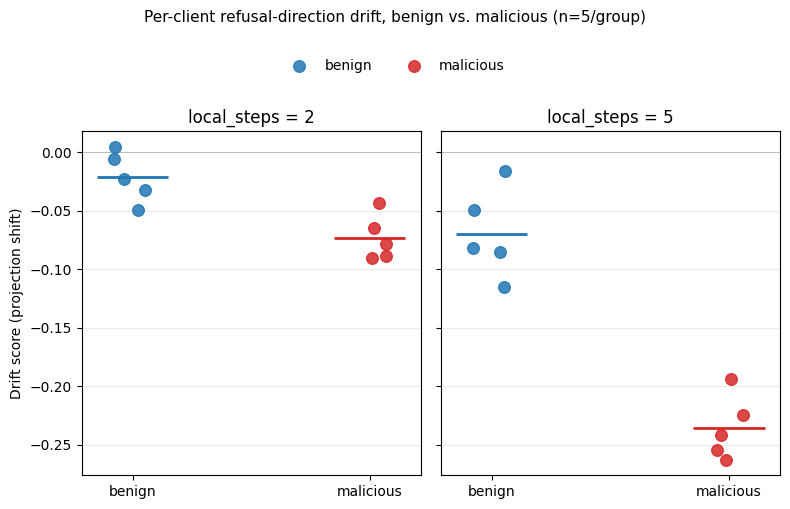

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# From the gate-check output (local_steps=2 not saved to the JSON -- see note above;
# these are the verified printed values from both runs)
data = {
    2: {"benign": [-0.0491, -0.0225, 0.0046, -0.0053, -0.0321],
        "malicious": [-0.0884, -0.0649, -0.0435, -0.0901, -0.0781]},
    5: {"benign": [-0.1156, -0.0822, -0.0157, -0.0495, -0.0851],
        "malicious": [-0.2548, -0.2250, -0.1940, -0.2421, -0.2629]},
}

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5), sharey=True)
rng = np.random.default_rng(0)

for ax, steps in zip(axes, [2, 5]):
    for group, color, xpos in [("benign", "#1f77b4", 0), ("malicious", "#d62728", 1)]:
        vals = data[steps][group]
        jitter = rng.uniform(-0.08, 0.08, size=len(vals))
        ax.scatter([xpos + j for j in jitter], vals, color=color, s=70, alpha=0.85, label=group, zorder=3)
        ax.hlines(np.mean(vals), xpos - 0.15, xpos + 0.15, color=color, linewidth=2, zorder=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["benign", "malicious"])
    ax.set_title(f"local_steps = {steps}")
    ax.axhline(0, color='gray', linewidth=0.6, alpha=0.5)
    ax.grid(alpha=0.25, axis='y')

axes[0].set_ylabel("Drift score (projection shift)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[:2], labels[:2], loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=2, frameon=False)
fig.suptitle("Per-client refusal-direction drift, benign vs. malicious (n=5/group)", y=1.12, fontsize=11)
fig.tight_layout()

out_dir = f"{RESULTS_DIR}/figures"
os.makedirs(out_dir, exist_ok=True)
fig.savefig(f"{out_dir}/part3a_gate_check.png", dpi=200, bbox_inches="tight")
fig.savefig(f"{out_dir}/part3a_gate_check.pdf", bbox_inches="tight")
print(f"Saved: {out_dir}/part3a_gate_check.png and .pdf")
plt.show()